## 1. Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

df = pd.read_csv("telco_cleaned_eda.csv")

display(df.head())
print("Dataset shape:", df.shape)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Churn Value,Churn Score,CLTV,Churn Reason,Monthly Charges_IQR_Outlier,Total Charges_IQR_Outlier,Tenure Months_IQR_Outlier,Monthly Charges_Capped,Total Charges_Capped,Tenure Months_Domain_Invalid
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,1,86,3239,Competitor made better offer,0,0,0,53.85,108.15,0
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,1,67,2701,Moved,0,0,0,70.70,151.65,0
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,1,86,5372,Moved,0,0,0,99.65,820.50,0
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,1,84,5003,Moved,0,0,0,104.80,3046.05,0
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,1,89,5340,Competitor had better devices,0,0,0,103.70,5036.30,0


Dataset shape: (7043, 39)


## 2. Prepare clustering features


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Candidate behavioral and value features
candidate_cols = [
    "Tenure Months",
    "Monthly Charge",
    "Monthly Charges",
    "Total Charges",
    "Total Revenue",
    "CLTV",
    "Churn Score",
    "Satisfaction Score"
]

# Keep only available columns
cluster_cols = [
    c for c in candidate_cols if c in df.columns
]

# Avoid duplicate information if both monthly charge columns exist
if "Monthly Charges" in cluster_cols and "Monthly Charge" in cluster_cols:
    cluster_cols.remove("Monthly Charge")

if len(cluster_cols) < 2:
    raise ValueError("Not enough numeric segmentation columns found.")

# Convert features to numeric
X = df[cluster_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# Impute missing values
imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(X)

X = pd.DataFrame(
    X_imputed,
    columns=cluster_cols,
    index=df.index
)

# Scale features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Clustering features:", cluster_cols)
print("Scaled data shape:", X_scaled.shape)

Clustering features: ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV', 'Churn Score']
Scaled data shape: (7043, 5)


## 3. Choose number of clusters using KMeans

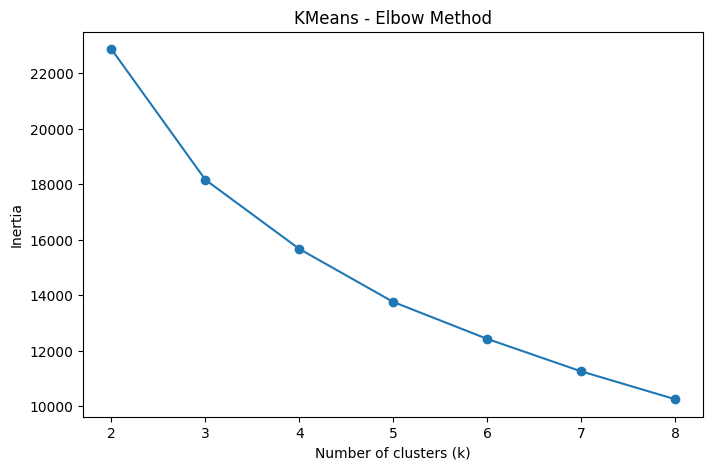

In [3]:
from sklearn.cluster import KMeans

inertias = []
k_values = range(2, 9)

for k in k_values:

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    km.fit(X_scaled)

    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("KMeans - Elbow Method")

plt.show()

## 4. KMeans silhouette analysis

In [4]:
from sklearn.metrics import silhouette_score

silhouette_results = []

for k in k_values:

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = km.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_results.append({
        "k": k,
        "silhouette_score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df)

# Select k with the highest silhouette score
best_k = int(
    silhouette_df.loc[
        silhouette_df["silhouette_score"].idxmax(),
        "k"
    ]
)

print("Selected number of clusters:", best_k)

,k,silhouette_score
0,2,0.320843
1,3,0.276740
2,4,0.265324
3,5,0.264936
4,6,0.268991
5,7,0.245913
6,8,0.247890


Selected number of clusters: 2


## 5. Fit final KMeans model

In [5]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

df["KMeans_Segment"] = kmeans.fit_predict(X_scaled)

print("KMeans cluster sizes:")

display(
    df["KMeans_Segment"]
    .value_counts()
    .sort_index()
)

print("KMeans cluster averages:")

display(
    df.groupby("KMeans_Segment")[cluster_cols]
    .mean()
    .round(2)
)

KMeans cluster sizes:


,count
KMeans_Segment,
0,2465
1,4578


KMeans cluster averages:


,Tenure Months,Monthly Charges,Total Charges,CLTV,Churn Score
KMeans_Segment,,,,,
0,58.28,84.38,4872.17,5110.29,53.74
1,18.42,54.20,885.98,4018.00,61.37


## 6. Apply DBSCAN clustering

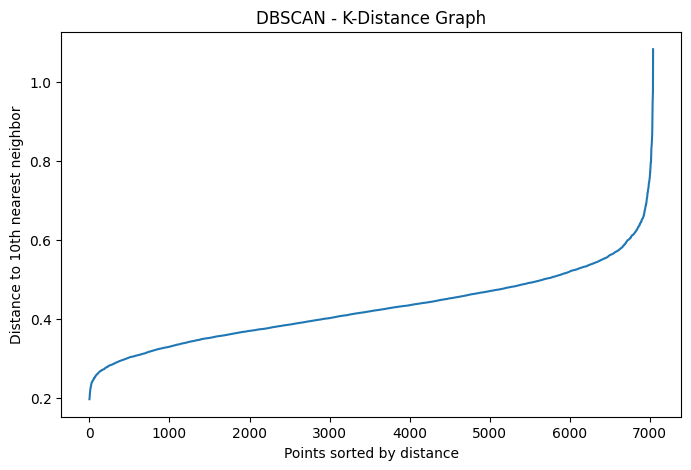

In [6]:
from sklearn.neighbors import NearestNeighbors

# Set minimum samples
min_samples = 10

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

# Sort distances to the kth nearest neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))

plt.plot(k_distances)

plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.title("DBSCAN - K-Distance Graph")

plt.show()

In [7]:
from sklearn.cluster import DBSCAN

# Initial DBSCAN parameters
dbscan = DBSCAN(
    eps=1.5,
    min_samples=min_samples
)

df["DBSCAN_Segment"] = dbscan.fit_predict(X_scaled)

print("DBSCAN cluster sizes:")

display(
    df["DBSCAN_Segment"]
    .value_counts()
    .sort_index()
)

# Number of clusters excluding noise (-1)
n_dbscan_clusters = len(
    set(df["DBSCAN_Segment"]) - {-1}
)

# Percentage of noise points
noise_percentage = (
    (df["DBSCAN_Segment"] == -1).mean() * 100
)

print("Number of DBSCAN clusters:", n_dbscan_clusters)
print(f"Noise percentage: {noise_percentage:.2f}%")

DBSCAN cluster sizes:


,count
DBSCAN_Segment,
0,7043


Number of DBSCAN clusters: 1
Noise percentage: 0.00%


## 7. Compare KMeans and DBSCAN

In [8]:
comparison = pd.DataFrame({
    "Algorithm": ["KMeans", "DBSCAN"],

    "Number of Clusters": [
        df["KMeans_Segment"].nunique(),
        n_dbscan_clusters
    ],

    "Number of Noise Points": [
        0,
        (df["DBSCAN_Segment"] == -1).sum()
    ],

    "Noise Percentage": [
        0,
        noise_percentage
    ]
})

display(comparison)

,Algorithm,Number of Clusters,Number of Noise Points,Noise Percentage
0,KMeans,2,0,0.0
1,DBSCAN,1,0,0.0


In [9]:
# KMeans silhouette
kmeans_silhouette = silhouette_score(
    X_scaled,
    df["KMeans_Segment"]
)

# DBSCAN silhouette excluding noise
dbscan_mask = df["DBSCAN_Segment"] != -1

dbscan_labels = df.loc[
    dbscan_mask,
    "DBSCAN_Segment"
]

if (
    dbscan_labels.nunique() >= 2
    and len(dbscan_labels) > dbscan_labels.nunique()
):
    dbscan_silhouette = silhouette_score(
        X_scaled[dbscan_mask.to_numpy()],
        dbscan_labels
    )
else:
    dbscan_silhouette = np.nan

silhouette_comparison = pd.DataFrame({
    "Algorithm": ["KMeans", "DBSCAN"],
    "Silhouette Score": [
        kmeans_silhouette,
        dbscan_silhouette
    ]
})

display(silhouette_comparison.round(4))

,Algorithm,Silhouette Score
0,KMeans,0.3208
1,DBSCAN,NaN


## 8. Profile each customer segment

In [10]:
# Create actual churn indicator for profiling only
if "Churn Label" in df.columns:

    churn_profile = df["Churn Label"].map({
        "Yes": 1,
        "No": 0
    })

elif "Churn Value" in df.columns:

    churn_profile = pd.to_numeric(
        df["Churn Value"],
        errors="coerce"
    )

else:
    churn_profile = pd.Series(
        np.nan,
        index=df.index
    )

df["Actual_Churn"] = churn_profile

In [11]:
# Identify available profile features
tenure_col = (
    "Tenure Months"
    if "Tenure Months" in df.columns
    else None
)

monthly_col = next(
    (
        c for c in ["Monthly Charges", "Monthly Charge"]
        if c in df.columns
    ),
    None
)

value_col = next(
    (
        c for c in ["CLTV", "Total Revenue", "Total Charges"]
        if c in df.columns
    ),
    None
)

risk_col = (
    "Churn Score"
    if "Churn Score" in df.columns
    else None
)

print("Tenure feature:", tenure_col)
print("Monthly spending feature:", monthly_col)
print("Customer value feature:", value_col)
print("Churn risk feature:", risk_col)

Tenure feature: Tenure Months
Monthly spending feature: Monthly Charges
Customer value feature: CLTV
Churn risk feature: Churn Score


In [12]:
def profile_segments(data, segment_col):

    # Calculate overall medians
    overall = {}

    for col in [tenure_col, monthly_col, value_col, risk_col]:
        if col is not None:
            overall[col] = data[col].median()

    # Calculate segment statistics
    summary = data.groupby(segment_col).agg(
        Customer_Count=(segment_col, "size")
    )

    summary["Percentage"] = (
        summary["Customer_Count"] / len(data) * 100
    )

    for col in [tenure_col, monthly_col, value_col, risk_col]:

        if col is not None:
            summary[col] = data.groupby(segment_col)[col].mean()

    # Actual churn rate
    summary["Actual_Churn_Rate"] = (
        data.groupby(segment_col)["Actual_Churn"].mean() * 100
    )

    # Assign business profiles
    profiles = {}

    for segment in summary.index:

        row = summary.loc[segment]

        # DBSCAN noise
        if segment == -1:
            profiles[segment] = "Noise / Unclassified"
            continue

        high_value = (
            value_col is not None
            and row[value_col] > overall[value_col]
        )

        high_spend = (
            monthly_col is not None
            and row[monthly_col] > overall[monthly_col]
        )

        long_tenure = (
            tenure_col is not None
            and row[tenure_col] > overall[tenure_col]
        )

        new_customer = (
            tenure_col is not None
            and row[tenure_col] <= overall[tenure_col]
        )

        high_risk = False

        if risk_col is not None:
            high_risk = row[risk_col] > overall[risk_col]

        elif pd.notna(row["Actual_Churn_Rate"]):
            high_risk = (
                row["Actual_Churn_Rate"]
                > data["Actual_Churn"].mean() * 100
            )

        # Business interpretation
        if high_value and high_risk:
            profile = "High-value at risk"

        elif new_customer and high_risk:
            profile = "New high-churn-risk"

        elif long_tenure and not high_spend:
            profile = "Loyal low-spend"

        elif high_value and not high_risk:
            profile = "High-value loyal customers"

        elif high_spend:
            profile = "High-spending customers"

        elif new_customer:
            profile = "New / developing customers"

        else:
            profile = "Regular customers"

        profiles[segment] = profile

    summary["Business_Profile"] = pd.Series(profiles)

    return summary.round(2)

## 9. Generate KMeans and DBSCAN business profiles

In [13]:
kmeans_profiles = profile_segments(
    df,
    "KMeans_Segment"
)

dbscan_profiles = profile_segments(
    df,
    "DBSCAN_Segment"
)

print("KMeans Customer Profiles:")
display(kmeans_profiles)

print("DBSCAN Customer Profiles:")
display(dbscan_profiles)

KMeans Customer Profiles:


,Customer_Count,Percentage,Tenure Months,Monthly Charges,CLTV,Churn Score,Actual_Churn_Rate,Business_Profile
KMeans_Segment,,,,,,,,
0,2465,35.0,58.28,84.38,5110.29,53.74,13.75,High-value loyal customers
1,4578,65.0,18.42,54.20,4018.00,61.37,33.42,New high-churn-risk


DBSCAN Customer Profiles:


,Customer_Count,Percentage,Tenure Months,Monthly Charges,CLTV,Churn Score,Actual_Churn_Rate,Business_Profile
DBSCAN_Segment,,,,,,,,
0,7043,100.0,32.37,64.76,4400.3,58.7,26.54,Loyal low-spend


In [14]:
# Create labeled segmentation
# Map cluster numbers to business profile names
kmeans_profile_map = (
    kmeans_profiles["Business_Profile"].to_dict()
)

dbscan_profile_map = (
    dbscan_profiles["Business_Profile"].to_dict()
)

df["KMeans_Profile"] = (
    df["KMeans_Segment"].map(kmeans_profile_map)
)

df["DBSCAN_Profile"] = (
    df["DBSCAN_Segment"].map(dbscan_profile_map)
)

display(
    df[[
        "KMeans_Segment",
        "KMeans_Profile",
        "DBSCAN_Segment",
        "DBSCAN_Profile"
    ]].head(10)
)

,KMeans_Segment,KMeans_Profile,DBSCAN_Segment,DBSCAN_Profile
0,1,New high-churn-risk,0,Loyal low-spend
1,1,New high-churn-risk,0,Loyal low-spend
2,1,New high-churn-risk,0,Loyal low-spend
3,0,High-value loyal customers,0,Loyal low-spend
4,0,High-value loyal customers,0,Loyal low-spend
5,1,New high-churn-risk,0,Loyal low-spend
6,1,New high-churn-risk,0,Loyal low-spend
7,1,New high-churn-risk,0,Loyal low-spend
8,0,High-value loyal customers,0,Loyal low-spend
9,1,New high-churn-risk,0,Loyal low-spend


## 10. Visualize clusters using PCA

In [15]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_scaled)

df["PCA1"] = X_pca[:, 0]
df["PCA2"] = X_pca[:, 1]

print(
    "Explained variance by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Explained variance by two components: 71.21 %


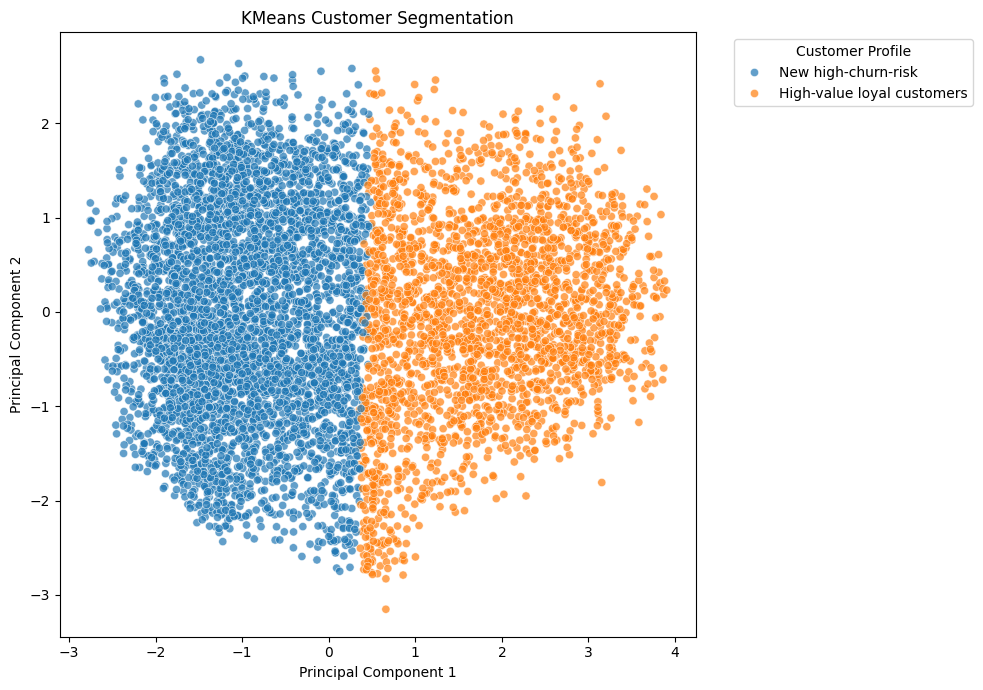

In [16]:
# KMeans visualization
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="PCA1",
    y="PCA2",
    hue="KMeans_Profile",
    palette="tab10",
    s=35,
    alpha=0.7
)

plt.title("KMeans Customer Segmentation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(
    title="Customer Profile",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

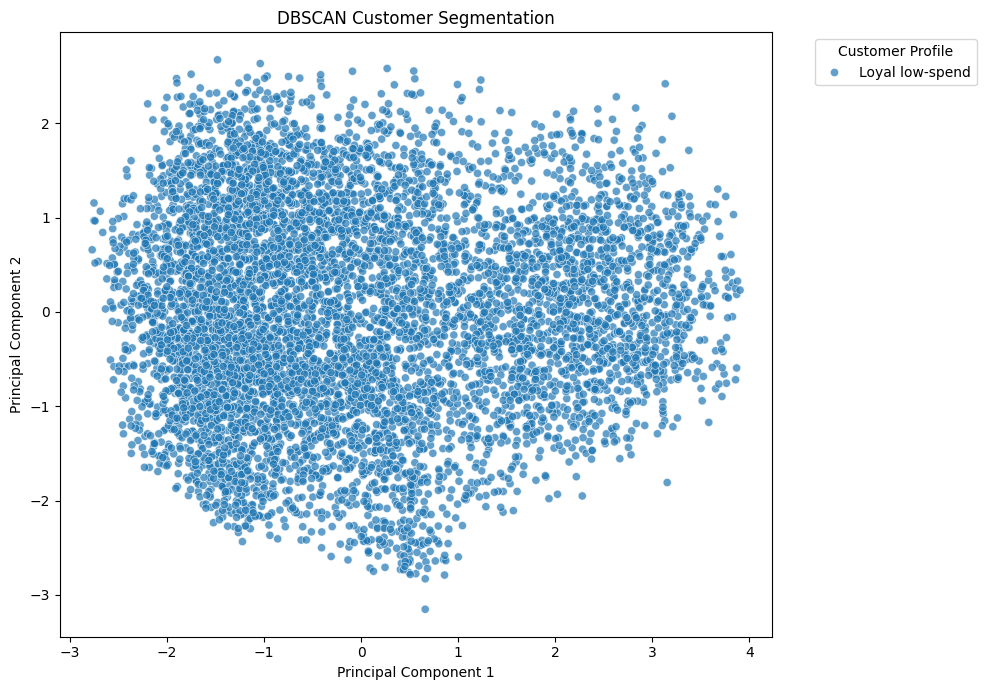

In [17]:
# DBSCAN visualization
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="PCA1",
    y="PCA2",
    hue="DBSCAN_Profile",
    palette="tab10",
    s=35,
    alpha=0.7
)

plt.title("DBSCAN Customer Segmentation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(
    title="Customer Profile",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## 11. Compare customer profiles between algorithms

In [18]:
print("KMeans profile distribution:")

display(
    df["KMeans_Profile"]
    .value_counts()
    .rename_axis("Customer Profile")
    .reset_index(name="Customer Count")
)

print("DBSCAN profile distribution:")

display(
    df["DBSCAN_Profile"]
    .value_counts()
    .rename_axis("Customer Profile")
    .reset_index(name="Customer Count")
)

KMeans profile distribution:


,Customer Profile,Customer Count
0,New high-churn-risk,4578
1,High-value loyal customers,2465


DBSCAN profile distribution:


,Customer Profile,Customer Count
0,Loyal low-spend,7043


In [19]:
# Compare actual churn rates by segment
churn_comparison = df.groupby(
    ["KMeans_Profile", "DBSCAN_Profile"],
    dropna=False
).agg(
    Customer_Count=("Actual_Churn", "size"),
    Average_Churn_Rate=("Actual_Churn", "mean")
).reset_index()

churn_comparison["Average_Churn_Rate"] *= 100

display(churn_comparison.round(2))

,KMeans_Profile,DBSCAN_Profile,Customer_Count,Average_Churn_Rate
0,High-value loyal customers,Loyal low-spend,2465,13.75
1,New high-churn-risk,Loyal low-spend,4578,33.42


## 12. Save segmented data and models

In [20]:
from pathlib import Path
import joblib

# Save segmented dataset
output_path = Path("telco_customer_segments.csv")

df.to_csv(output_path, index=False)

print("Segmented dataset saved successfully!")
print("File:", output_path.resolve())

# Save preprocessing objects and KMeans model
joblib.dump(imputer, "segment_imputer.pkl")
joblib.dump(scaler, "segment_scaler.pkl")
joblib.dump(kmeans, "kmeans_model.pkl")

# Save DBSCAN model and parameters
joblib.dump(dbscan, "dbscan_model.pkl")

# Save PCA model
joblib.dump(pca, "segment_pca.pkl")

# Verify saved files
files_to_check = [
    "telco_customer_segments.csv",
    "segment_imputer.pkl",
    "segment_scaler.pkl",
    "kmeans_model.pkl",
    "dbscan_model.pkl",
    "segment_pca.pkl"
]

for file in files_to_check:

    path = Path(file)

    if path.exists() and path.stat().st_size > 0:
        print(f"{file}: Saved successfully")
    else:
        print(f"{file}: Saving failed!")

Segmented dataset saved successfully!
File: /content/telco_customer_segments.csv
telco_customer_segments.csv: Saved successfully
segment_imputer.pkl: Saved successfully
segment_scaler.pkl: Saved successfully
kmeans_model.pkl: Saved successfully
dbscan_model.pkl: Saved successfully
segment_pca.pkl: Saved successfully


## 13. Business interpretation

## 1. K-Means Clustering
K-Means divides customers into a predefined number of clusters based on similarities in their characteristics. Each cluster represents a group of customers with similar behavioral and financial patterns.

## 2. DBSCAN Clustering
DBSCAN identifies clusters based on customer density and can detect outliers (noise points). Unlike K-Means, it does not require specifying the number of clusters in advance.

## 3. Comparison Between K-Means and DBSCAN
The two algorithms were compared based on:
- Number of identified clusters.
- Number and percentage of noise points detected by DBSCAN.
- Silhouette score, where applicable.
- Interpretability and business usefulness of the resulting segments.

## 4. Business Interpretation
Customer profiles were created using characteristics such as tenure, monthly charges, customer value, and churn risk.

Possible customer segments include:
- **High-value at-risk customers:** Customers with high value and high churn risk.
- **High-value loyal customers:** Valuable customers with relatively low churn risk.
- **New customers:** Customers with relatively short tenure.
- **Loyal low-spend customers:** Long-term customers with relatively low spending.
- **Noise / Unclassified customers:** Customers that DBSCAN could not assign to a dense cluster.

These labels are descriptive interpretations based on cluster characteristics, not predefined categories.

## 5. Business Recommendations
- Focus retention campaigns on high-value customers at risk of churning.
- Encourage new customers to adopt additional services.
- Maintain loyalty programs for valuable long-term customers.
- Investigate DBSCAN noise points separately to identify unusual customer behavior.

## 6. Conclusion
K-Means provides clearly defined customer segments, while DBSCAN helps identify dense customer groups and unusual observations. Combining both approaches provides additional insights into customer behavior and supports data-driven marketing and retention strategies.